
# Ejercicio — MDP en GridWorld 10×10

Este notebook construye un **laberinto/grid de 10×10** y lo resuelve como un **Markov Decision Process (MDP)**.

1. Construcción del MDP.
2. Validación de probabilidades.
3. Value Iteration.
4. Extracción de la política óptima.
5. Policy Iteration.
6. Comparación entre ambos algoritmos.
7. Mostrar el camino de máxima recompensa desde `START` hasta `GOAL`.
8. Calcular recompensa acumulada y recompensa descontada.

## Notación

Estado:

$$
s=(row,col)
$$

Transición:

$$
T(s,a,s')=P(s'\mid s,a)
$$

Recompensa:

$$
R(s)
$$

Value Iteration:

$$
V_{k+1}(s)
=
R(s)+
\gamma
\max_a
\sum_{s'}T(s,a,s')V_k(s')
$$

Policy Evaluation:

$$
V_{k+1}^{\pi}(s)
=
R(s)+
\gamma
\sum_{s'}T(s,\pi(s),s')V_k^\pi(s')
$$



## 1. Construcción del MDP

El mundo se genera de manera pseudoaleatoria utilizando una semilla fija.

Así obtenemos:

- un grid de **10×10**;
- un punto inicial `START`;
- una meta `GOAL`;
- obstáculos;
- recompensas positivas y negativas;
- un factor de descuento $\gamma$ generado aleatoriamente;
- probabilidades de movimiento diferentes para cada posición.

Para cada estado se genera:

- probabilidad de avanzar en la dirección elegida;
- probabilidad de desviarse a la izquierda;
- probabilidad de desviarse a la derecha.

Las tres probabilidades siempre suman 1.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque, defaultdict

SEED = 42

UP    = (-1, 0)
DOWN  = ( 1, 0)
LEFT  = ( 0,-1)
RIGHT = ( 0, 1)

ARROWS = {
    UP: "↑",
    DOWN: "↓",
    LEFT: "←",
    RIGHT: "→",
}


class RandomGridMDP:
    """
    GridWorld 10x10 usando la notación de clase:

        state = (row, col)
        action = (dr, dc)
        R(s) = recompensa del estado actual
        T(s,a,s') = P(s' | s,a)

    El mapa, las recompensas y las probabilidades se generan
    pseudoaleatoriamente con una semilla fija.
    """

    def __init__(self, height=10, width=10, seed=42):
        self.height = height
        self.width = width
        self.seed = seed
        self.rng = np.random.default_rng(seed)

        self.start = (height - 1, 0)
        self.goal = (0, width - 1)

        self.actions = [UP, DOWN, LEFT, RIGHT]

        # Parámetros aleatorios del MDP.
        self.gamma = float(self.rng.uniform(0.88, 0.97))
        self.living_reward = float(self.rng.uniform(-1.2, -0.5))
        self.goal_reward = float(self.rng.uniform(15.0, 25.0))

        # Generar un laberinto que conserve al menos un camino START -> GOAL.
        self.walls = self._generate_valid_walls(obstacle_probability=0.18)

        # Estados transitables.
        available = [
            s for s in self._all_coordinates()
            if s not in self.walls
            and s not in {self.start, self.goal}
        ]

        self.rng.shuffle(available)

        # Algunas celdas tendrán recompensa negativa o positiva.
        n_dangers = 8
        n_bonuses = 6

        danger_cells = available[:n_dangers]
        bonus_cells = available[n_dangers:n_dangers+n_bonuses]

        self.danger_states = {
            s: float(self.rng.uniform(-8.0, -3.0))
            for s in danger_cells
        }

        self.bonus_states = {
            s: float(self.rng.uniform(1.0, 5.0))
            for s in bonus_cells
        }

        self.terminal_states = {
            self.goal: self.goal_reward
        }

        # Probabilidades diferentes para cada estado.
        self.transition_weights = {}

        for s in self.states():
            if self.is_terminal(s):
                continue

            # Probabilidad de ir en la dirección deseada.
            p_intended = float(self.rng.uniform(0.55, 0.90))

            # El resto se divide de forma aleatoria entre izquierda y derecha.
            remaining = 1.0 - p_intended
            split = float(self.rng.uniform(0.35, 0.65))

            p_left = remaining * split
            p_right = remaining - p_left

            self.transition_weights[s] = {
                "intended": p_intended,
                "left": p_left,
                "right": p_right,
            }

    def _all_coordinates(self):
        return [
            (r, c)
            for r in range(self.height)
            for c in range(self.width)
        ]

    def _path_exists(self, walls):
        """Comprueba mediante BFS que START y GOAL estén conectados."""
        queue = deque([self.start])
        visited = {self.start}

        while queue:
            state = queue.popleft()

            if state == self.goal:
                return True

            for action in self.actions:
                nr = state[0] + action[0]
                nc = state[1] + action[1]
                nxt = (nr, nc)

                if (
                    0 <= nr < self.height
                    and 0 <= nc < self.width
                    and nxt not in walls
                    and nxt not in visited
                ):
                    visited.add(nxt)
                    queue.append(nxt)

        return False

    def _generate_valid_walls(self, obstacle_probability=0.18):
        """
        Genera obstáculos aleatorios.
        Si el mapa queda sin camino START -> GOAL, vuelve a intentarlo.
        """
        while True:
            walls = set()

            for s in self._all_coordinates():
                if s in {self.start, self.goal}:
                    continue

                if self.rng.random() < obstacle_probability:
                    walls.add(s)

            if self._path_exists(walls):
                return walls

    def is_valid_state(self, state):
        r, c = state

        if not (0 <= r < self.height and 0 <= c < self.width):
            return False

        return state not in self.walls

    def states(self):
        return [
            s for s in self._all_coordinates()
            if self.is_valid_state(s)
        ]

    def is_terminal(self, state):
        return state in self.terminal_states

    def get_reward(self, state):
        """
        Implementa R(s).
        """
        if state in self.terminal_states:
            return self.terminal_states[state]

        if state in self.danger_states:
            return self.danger_states[state]

        if state in self.bonus_states:
            return self.bonus_states[state]

        return self.living_reward

    def _move(self, state, action):
        """
        Intenta ejecutar una acción.
        Si sale del grid o golpea un obstáculo,
        el agente permanece en el mismo estado.
        """
        candidate = (
            state[0] + action[0],
            state[1] + action[1]
        )

        if self.is_valid_state(candidate):
            return candidate

        return state

    def _left_of(self, action):
        dr, dc = action
        return (-dc, dr)

    def _right_of(self, action):
        dr, dc = action
        return (dc, -dr)

    def get_transition_probs(self, state, action):
        """
        Devuelve:
            [(next_state, probability), ...]

        T(s,a,s') = P(s' | s,a)

        Las probabilidades dependen del estado actual.
        """

        # Estado terminal absorbente.
        if self.is_terminal(state):
            return [(state, 1.0)]

        probs = self.transition_weights[state]

        possible_moves = [
            (action, probs["intended"]),
            (self._left_of(action), probs["left"]),
            (self._right_of(action), probs["right"]),
        ]

        # Puede ocurrir que diferentes movimientos terminen
        # en el mismo estado por culpa de paredes o bordes.
        accumulated = defaultdict(float)

        for actual_action, probability in possible_moves:
            next_state = self._move(state, actual_action)
            accumulated[next_state] += probability

        return list(accumulated.items())



## 2. Crear y validar el mundo

Antes de aplicar Bellman verificamos que cada distribución:

$$
\sum_{s'}T(s,a,s')=1
$$

También mostramos los parámetros aleatorios generados.


In [2]:

grid = RandomGridMDP(seed=SEED)

print("START:", grid.start)
print("GOAL:", grid.goal)
print("Número de obstáculos:", len(grid.walls))
print("Número de estados transitables:", len(grid.states()))
print(f"Living reward: {grid.living_reward:.3f}")
print(f"Recompensa GOAL: {grid.goal_reward:.3f}")
print(f"Gamma: {grid.gamma:.4f}")

for s in grid.states():
    for a in grid.actions:
        transitions = grid.get_transition_probs(s, a)
        total = sum(p for _, p in transitions)
        assert abs(total - 1.0) < 1e-12

print("\n✓ Todas las distribuciones de transición suman 1.")


START: (9, 0)
GOAL: (0, 9)
Número de obstáculos: 19
Número de estados transitables: 81
Living reward: -0.893
Recompensa GOAL: 23.586
Gamma: 0.9497

✓ Todas las distribuciones de transición suman 1.



## 3. Visualización del grid

En cada celda transitable mostramos:

- su recompensa $R(s)$;
- la probabilidad de ejecutar correctamente la acción elegida.

Los obstáculos se muestran como `WALL`.


In [3]:

def print_world(grid):
    for r in range(grid.height):
        row = []

        for c in range(grid.width):
            s = (r, c)

            if s in grid.walls:
                text = "  WALL  "

            elif s == grid.start:
                p = grid.transition_weights[s]["intended"]
                text = f"START\np={p:.2f}"

            elif s == grid.goal:
                text = f"GOAL\nR={grid.get_reward(s):+.1f}"

            else:
                reward = grid.get_reward(s)
                p = grid.transition_weights[s]["intended"]
                text = f"R={reward:+.1f}\np={p:.2f}"

            row.append(f"{text:^14}")

        print(" | ".join(row))


print_world(grid)


R=-0.9
p=0.73  |      WALL      | R=-0.9
p=0.88  | R=-0.9
p=0.57  | R=-3.4
p=0.90  |      WALL      | R=-0.9
p=0.81  | R=-0.9
p=0.86  | R=-4.2
p=0.66  |  GOAL
R=+23.6 
R=-0.9
p=0.78  | R=-0.9
p=0.58  | R=-0.9
p=0.64  | R=-0.9
p=0.63  | R=-0.9
p=0.84  |      WALL      | R=-0.9
p=0.61  | R=-0.9
p=0.86  | R=-0.9
p=0.66  | R=-0.9
p=0.89 
R=-0.9
p=0.60  | R=-0.9
p=0.63  | R=-0.9
p=0.79  | R=-0.9
p=0.73  | R=-0.9
p=0.75  |      WALL      |      WALL      | R=-0.9
p=0.83  | R=-0.9
p=0.81  | R=-0.9
p=0.59 
R=-0.9
p=0.69  | R=-0.9
p=0.72  | R=-0.9
p=0.88  | R=-0.9
p=0.87  |      WALL      | R=-0.9
p=0.74  | R=-0.9
p=0.59  | R=-0.9
p=0.70  | R=-0.9
p=0.76  | R=-0.9
p=0.83 
R=-0.9
p=0.82  | R=-0.9
p=0.59  | R=-0.9
p=0.83  | R=-0.9
p=0.74  | R=-4.4
p=0.85  | R=-0.9
p=0.69  | R=-0.9
p=0.70  |      WALL      | R=-0.9
p=0.85  |      WALL     
R=-0.9
p=0.64  | R=-0.9
p=0.81  | R=-0.9
p=0.59  | R=-0.9
p=0.76  | R=-0.9
p=0.84  | R=+4.2
p=0.60  |      WALL      |      WALL      | R=-0.9
p=0.61  | R=-0.9


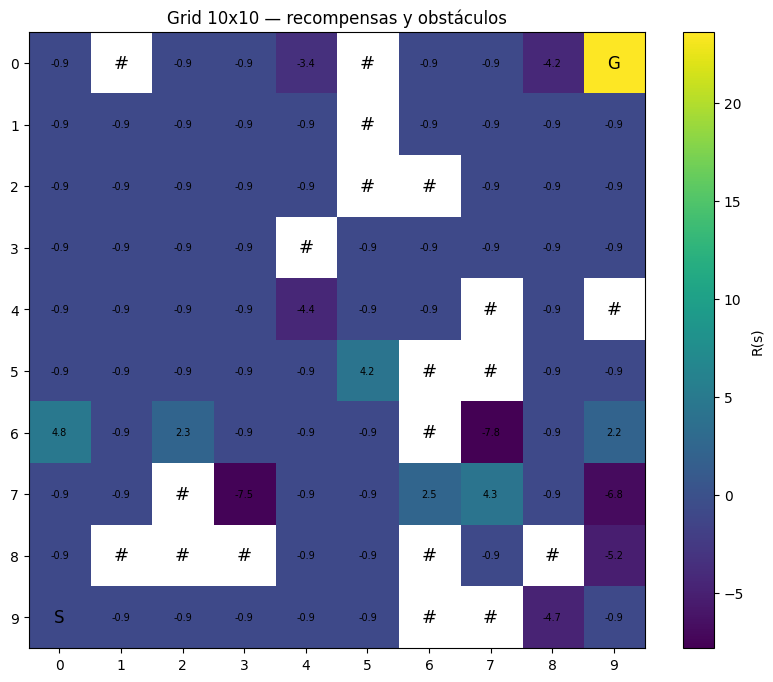

In [4]:

def plot_rewards(grid):
    values = np.full((grid.height, grid.width), np.nan)

    for r in range(grid.height):
        for c in range(grid.width):
            s = (r, c)
            if s not in grid.walls:
                values[r, c] = grid.get_reward(s)

    plt.figure(figsize=(10, 8))
    plt.imshow(values)
    plt.colorbar(label="R(s)")

    for r in range(grid.height):
        for c in range(grid.width):
            s = (r, c)

            if s in grid.walls:
                plt.text(c, r, "#", ha="center", va="center", fontsize=13)
            elif s == grid.start:
                plt.text(c, r, "S", ha="center", va="center", fontsize=12)
            elif s == grid.goal:
                plt.text(c, r, "G", ha="center", va="center", fontsize=12)
            else:
                plt.text(
                    c, r,
                    f"{grid.get_reward(s):.1f}",
                    ha="center",
                    va="center",
                    fontsize=7
                )

    plt.xticks(range(grid.width))
    plt.yticks(range(grid.height))
    plt.title("Grid 10x10 — recompensas y obstáculos")
    plt.show()


plot_rewards(grid)



## 4. Value Iteration

Para una acción fija:

$$
Q_V(s,a)
=
\sum_{s'}T(s,a,s')V(s')
$$

y actualizamos:

$$
V_{k+1}(s)
=
R(s)
+
\gamma
\max_aQ_{V_k}(s,a)
$$


In [5]:

def expected_next_value(grid, state, action, V):
    """
    Implementa:

        Σ T(s,a,s') V(s')
    """
    return sum(
        probability * V[next_state]
        for next_state, probability
        in grid.get_transition_probs(state, action)
    )


def value_iteration(grid, threshold=1e-4, max_iter=10_000):
    """
    Bellman de optimalidad:

    V_{k+1}(s)
        =
    R(s) + gamma max_a Σ T(s,a,s')V_k(s')
    """

    V = {
        state: 0.0
        for state in grid.states()
    }

    deltas = []

    for iteration in range(max_iter):
        V_new = V.copy()
        biggest_change = 0.0

        for state in grid.states():

            if grid.is_terminal(state):
                V_new[state] = grid.get_reward(state)

            else:
                best_expected_future = max(
                    expected_next_value(
                        grid,
                        state,
                        action,
                        V
                    )
                    for action in grid.actions
                )

                V_new[state] = (
                    grid.get_reward(state)
                    +
                    grid.gamma * best_expected_future
                )

            biggest_change = max(
                biggest_change,
                abs(V_new[state] - V[state])
            )

        V = V_new
        deltas.append(biggest_change)

        if biggest_change < threshold:
            return V, iteration + 1, deltas

    return V, max_iter, deltas


def extract_policy(grid, V):
    """
    pi*(s)
       =
    argmax_a Σ T(s,a,s') V*(s')
    """

    policy = {}

    for state in grid.states():

        if grid.is_terminal(state):
            continue

        policy[state] = max(
            grid.actions,
            key=lambda action: expected_next_value(
                grid,
                state,
                action,
                V
            )
        )

    return policy


In [6]:

V_vi, iterations_vi, deltas_vi = value_iteration(grid)
policy_vi = extract_policy(grid, V_vi)

print("Value Iteration convergió en", iterations_vi, "iteraciones.")
print(f"V*(START) = {V_vi[grid.start]:.4f}")


Value Iteration convergió en 196 iteraciones.
V*(START) = 32.9070



## 5. Política óptima obtenida con Value Iteration

Cada flecha representa:

$$
\pi^*(s)
=
\arg\max_a
\sum_{s'}T(s,a,s')V^*(s')
$$


In [7]:

def print_policy(grid, policy):
    for r in range(grid.height):
        row = []

        for c in range(grid.width):
            s = (r, c)

            if s in grid.walls:
                row.append(" # ")

            elif s == grid.goal:
                row.append(" G ")

            elif s == grid.start:
                row.append("S" + ARROWS[policy[s]])

            else:
                row.append(" " + ARROWS[policy[s]] + " ")

        print(" | ".join(row))


print("POLÍTICA ÓPTIMA — VALUE ITERATION\n")
print_policy(grid, policy_vi)


POLÍTICA ÓPTIMA — VALUE ITERATION

 ↓  |  #  |  ↓  |  ←  |  ↓  |  #  |  →  |  ↓  |  →  |  G 
 ↓  |  ↓  |  ↓  |  ↓  |  ↓  |  #  |  →  |  ↓  |  ↓  |  ↑ 
 ↓  |  ↓  |  ↓  |  ↓  |  ←  |  #  |  #  |  ↓  |  ↓  |  ← 
 ↓  |  ↓  |  ↓  |  ↓  |  #  |  ↓  |  ←  |  ←  |  ↓  |  ← 
 ↓  |  ↓  |  ↓  |  ↓  |  ↓  |  ↓  |  ←  |  #  |  ↓  |  # 
 ↓  |  ←  |  ↓  |  →  |  →  |  →  |  #  |  #  |  ↓  |  ↓ 
 ←  |  ←  |  ←  |  ←  |  →  |  ↑  |  #  |  ↓  |  ↓  |  ← 
 ↑  |  ←  |  #  |  →  |  →  |  →  |  →  |  ←  |  ←  |  ← 
 ↑  |  #  |  #  |  #  |  ↑  |  ↑  |  #  |  ↑  |  #  |  ↑ 
S↑ |  ←  |  ←  |  →  |  →  |  ↑  |  #  |  #  |  →  |  ↑ 



## 6. Policy Iteration

Policy Iteration separa el procedimiento en dos etapas.

### Policy Evaluation

$$
V_{k+1}^{\pi}(s)
=
R(s)
+
\gamma
\sum_{s'}T(s,\pi(s),s')V_k^\pi(s')
$$

### Policy Improvement

$$
\pi_{\text{new}}(s)
=
\arg\max_a
\sum_{s'}T(s,a,s')V^\pi(s')
$$


In [8]:

def policy_evaluation(grid, policy, threshold=1e-4, max_iter=10_000):

    V = {
        state: 0.0
        for state in grid.states()
    }

    for iteration in range(max_iter):
        V_new = V.copy()
        biggest_change = 0.0

        for state in grid.states():

            if grid.is_terminal(state):
                V_new[state] = grid.get_reward(state)

            else:
                action = policy[state]

                V_new[state] = (
                    grid.get_reward(state)
                    +
                    grid.gamma
                    * expected_next_value(
                        grid,
                        state,
                        action,
                        V
                    )
                )

            biggest_change = max(
                biggest_change,
                abs(V_new[state] - V[state])
            )

        V = V_new

        if biggest_change < threshold:
            return V, iteration + 1

    return V, max_iter


def policy_improvement(grid, V):

    new_policy = {}

    for state in grid.states():

        if grid.is_terminal(state):
            continue

        new_policy[state] = max(
            grid.actions,
            key=lambda action: expected_next_value(
                grid,
                state,
                action,
                V
            )
        )

    return new_policy


def policy_iteration(grid, threshold=1e-4, max_iter=100):

    # Política inicial arbitraria: RIGHT.
    policy = {
        state: RIGHT
        for state in grid.states()
        if not grid.is_terminal(state)
    }

    history = []

    for iteration in range(max_iter):

        V, evaluation_sweeps = policy_evaluation(
            grid,
            policy,
            threshold=threshold
        )

        new_policy = policy_improvement(grid, V)

        changed = sum(
            new_policy[state] != policy[state]
            for state in new_policy
        )

        history.append({
            "policy_iteration": iteration + 1,
            "evaluation_sweeps": evaluation_sweeps,
            "changed_actions": changed,
        })

        policy = new_policy

        if changed == 0:
            break

    V, _ = policy_evaluation(
        grid,
        policy,
        threshold=threshold
    )

    return policy, V, history


In [9]:

policy_pi, V_pi, history = policy_iteration(grid)

print("Historia de Policy Iteration:")
for item in history:
    print(item)

print("\nPOLÍTICA ÓPTIMA — POLICY ITERATION\n")
print_policy(grid, policy_pi)

same_policy = policy_vi == policy_pi

print("\n¿Ambos algoritmos encontraron la misma política?")
print(same_policy)

assert same_policy
print("✓ Value Iteration y Policy Iteration coinciden.")


Historia de Policy Iteration:
{'policy_iteration': 1, 'evaluation_sweeps': 199, 'changed_actions': 68}
{'policy_iteration': 2, 'evaluation_sweeps': 188, 'changed_actions': 33}
{'policy_iteration': 3, 'evaluation_sweeps': 195, 'changed_actions': 19}
{'policy_iteration': 4, 'evaluation_sweeps': 195, 'changed_actions': 10}
{'policy_iteration': 5, 'evaluation_sweeps': 196, 'changed_actions': 9}
{'policy_iteration': 6, 'evaluation_sweeps': 196, 'changed_actions': 6}
{'policy_iteration': 7, 'evaluation_sweeps': 196, 'changed_actions': 1}
{'policy_iteration': 8, 'evaluation_sweeps': 196, 'changed_actions': 0}

POLÍTICA ÓPTIMA — POLICY ITERATION

 ↓  |  #  |  ↓  |  ←  |  ↓  |  #  |  →  |  ↓  |  →  |  G 
 ↓  |  ↓  |  ↓  |  ↓  |  ↓  |  #  |  →  |  ↓  |  ↓  |  ↑ 
 ↓  |  ↓  |  ↓  |  ↓  |  ←  |  #  |  #  |  ↓  |  ↓  |  ← 
 ↓  |  ↓  |  ↓  |  ↓  |  #  |  ↓  |  ←  |  ←  |  ↓  |  ← 
 ↓  |  ↓  |  ↓  |  ↓  |  ↓  |  ↓  |  ←  |  #  |  ↓  |  # 
 ↓  |  ←  |  ↓  |  →  |  →  |  →  |  #  |  #  |  ↓  |  ↓ 
 ←  |


## 7. Camino de máxima recompensa

Como las transiciones son probabilísticas, una misma acción puede terminar en diferentes estados.

Para **mostrar un recorrido representativo de la política óptima**, en cada paso:

1. consultamos la acción recomendada por $\pi^*$;
2. consultamos $T(s,a,s')$;
3. escogemos el estado siguiente con **mayor probabilidad**.

Esto nos permite visualizar el recorrido más probable producido por la política óptima.


In [10]:

def most_probable_path(grid, policy, max_steps=200):

    state = grid.start
    path = [state]
    details = []

    visited_counter = defaultdict(int)

    for step in range(max_steps):

        if grid.is_terminal(state):
            break

        action = policy[state]
        transitions = grid.get_transition_probs(state, action)

        next_state, probability = max(
            transitions,
            key=lambda item: item[1]
        )

        details.append({
            "step": step,
            "state": state,
            "action": ARROWS[action],
            "next_state": next_state,
            "probability": probability,
            "reward_state": grid.get_reward(state),
        })

        state = next_state
        path.append(state)

        visited_counter[state] += 1

        # Protección contra ciclos.
        if visited_counter[state] > 5:
            print("Se detectó un ciclo en el recorrido más probable.")
            break

    return path, details


path, path_details = most_probable_path(
    grid,
    policy_vi
)

print("Recorrido más probable:")
print(path)

print("\nNúmero de movimientos:", len(path) - 1)
print("¿Llegó a GOAL?:", path[-1] == grid.goal)


Se detectó un ciclo en el recorrido más probable.
Recorrido más probable:
[(9, 0), (8, 0), (7, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0)]

Número de movimientos: 8
¿Llegó a GOAL?: False



## 8. Pesos de probabilidad del recorrido

En cada paso mostramos la probabilidad asociada al movimiento que efectivamente forma parte del recorrido mostrado.


In [11]:

for item in path_details:
    print(
        f"Paso {item['step']:2d}: "
        f"{item['state']} "
        f"--{item['action']}--> "
        f"{item['next_state']} | "
        f"P={item['probability']:.3f} | "
        f"R(s)={item['reward_state']:+.3f}"
    )


Paso  0: (9, 0) --↑--> (8, 0) | P=0.665 | R(s)=-0.893
Paso  1: (8, 0) --↑--> (7, 0) | P=0.712 | R(s)=-0.893
Paso  2: (7, 0) --↑--> (6, 0) | P=0.681 | R(s)=-0.893
Paso  3: (6, 0) --←--> (6, 0) | P=0.557 | R(s)=+4.812
Paso  4: (6, 0) --←--> (6, 0) | P=0.557 | R(s)=+4.812
Paso  5: (6, 0) --←--> (6, 0) | P=0.557 | R(s)=+4.812
Paso  6: (6, 0) --←--> (6, 0) | P=0.557 | R(s)=+4.812
Paso  7: (6, 0) --←--> (6, 0) | P=0.557 | R(s)=+4.812



## 9. Recompensa total y descuento

La recompensa acumulada sin descuento es:

$$
G
=
\sum_{t=0}^{T}R(s_t)
$$

La recompensa descontada es:

$$
G_\gamma
=
\sum_{t=0}^{T}
\gamma^tR(s_t)
$$

El descuento hace que las recompensas cercanas tengan más peso que las recompensas muy lejanas.


In [12]:

def calculate_returns(grid, path):

    total_reward = 0.0
    discounted_reward = 0.0

    table = []

    for t, state in enumerate(path):
        reward = grid.get_reward(state)
        discount_factor = grid.gamma ** t
        discounted_value = discount_factor * reward

        total_reward += reward
        discounted_reward += discounted_value

        table.append({
            "t": t,
            "state": state,
            "reward": reward,
            "gamma^t": discount_factor,
            "discounted_reward": discounted_value,
        })

    return total_reward, discounted_reward, table


total_reward, discounted_reward, reward_table = calculate_returns(
    grid,
    path
)

print(f"Gamma = {grid.gamma:.4f}")
print(f"Recompensa acumulada = {total_reward:.4f}")
print(f"Recompensa descontada = {discounted_reward:.4f}")

print("\nDetalle:")
for item in reward_table:
    print(
        f"t={item['t']:2d} | "
        f"s={item['state']} | "
        f"R={item['reward']:+7.3f} | "
        f"gamma^t={item['gamma^t']:.5f} | "
        f"aporte={item['discounted_reward']:+8.3f}"
    )


Gamma = 0.9497
Recompensa acumulada = 26.1912
Recompensa descontada = 19.2687

Detalle:
t= 0 | s=(9, 0) | R= -0.893 | gamma^t=1.00000 | aporte=  -0.893
t= 1 | s=(8, 0) | R= -0.893 | gamma^t=0.94966 | aporte=  -0.848
t= 2 | s=(7, 0) | R= -0.893 | gamma^t=0.90185 | aporte=  -0.805
t= 3 | s=(6, 0) | R= +4.812 | gamma^t=0.85644 | aporte=  +4.121
t= 4 | s=(6, 0) | R= +4.812 | gamma^t=0.81333 | aporte=  +3.913
t= 5 | s=(6, 0) | R= +4.812 | gamma^t=0.77238 | aporte=  +3.716
t= 6 | s=(6, 0) | R= +4.812 | gamma^t=0.73350 | aporte=  +3.529
t= 7 | s=(6, 0) | R= +4.812 | gamma^t=0.69657 | aporte=  +3.352
t= 8 | s=(6, 0) | R= +4.812 | gamma^t=0.66150 | aporte=  +3.183



## 10. Visualización del recorrido

- `S`: punto inicial.
- `G`: objetivo.
- `#`: obstáculo.
- Los números indican el orden del recorrido.


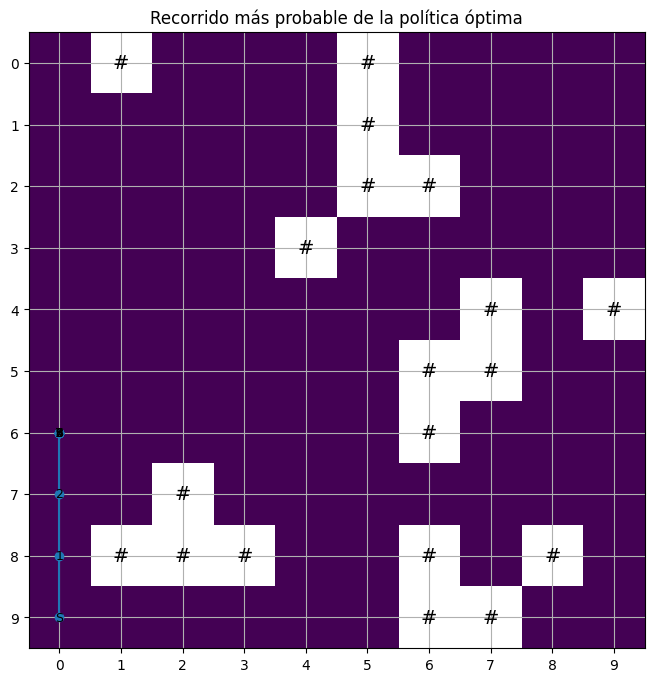

In [13]:

def plot_path(grid, path):

    background = np.zeros(
        (grid.height, grid.width)
    )

    for wall in grid.walls:
        background[wall] = np.nan

    plt.figure(figsize=(10, 8))
    plt.imshow(background)

    # Obstáculos.
    for r, c in grid.walls:
        plt.text(
            c, r, "#",
            ha="center",
            va="center",
            fontsize=14
        )

    # Camino.
    xs = [c for r, c in path]
    ys = [r for r, c in path]

    plt.plot(xs, ys, marker="o")

    for i, (r, c) in enumerate(path):
        label = str(i)

        if (r, c) == grid.start:
            label = "S"
        elif (r, c) == grid.goal:
            label = "G"

        plt.text(
            c, r, label,
            ha="center",
            va="center",
            fontsize=9
        )

    plt.xticks(range(grid.width))
    plt.yticks(range(grid.height))
    plt.grid()
    plt.title("Recorrido más probable de la política óptima")
    plt.show()


plot_path(grid, path)



## 11. Simulación estocástica

El recorrido anterior usa siempre el siguiente estado **más probable**.

Pero un MDP es estocástico. Por eso también podemos ejecutar una simulación real:

$$
s_{t+1}\sim T(s_t,\pi(s_t),s')
$$

En cada paso se sortea el siguiente estado utilizando sus probabilidades.


In [14]:

def stochastic_rollout(grid, policy, seed=123, max_steps=200):

    rng = np.random.default_rng(seed)

    state = grid.start
    path = [state]

    for _ in range(max_steps):

        if grid.is_terminal(state):
            break

        action = policy[state]
        transitions = grid.get_transition_probs(
            state,
            action
        )

        next_states = [
            next_state
            for next_state, probability
            in transitions
        ]

        probabilities = [
            probability
            for next_state, probability
            in transitions
        ]

        index = rng.choice(
            len(next_states),
            p=probabilities
        )

        state = next_states[index]
        path.append(state)

    return path


random_path = stochastic_rollout(
    grid,
    policy_vi,
    seed=7
)

random_total, random_discounted, _ = calculate_returns(
    grid,
    random_path
)

print("Recorrido estocástico:")
print(random_path)

print("\nLlegó a GOAL:", random_path[-1] == grid.goal)
print("Movimientos:", len(random_path) - 1)
print(f"Recompensa acumulada: {random_total:.4f}")
print(f"Recompensa descontada: {random_discounted:.4f}")


Recorrido estocástico:
[(9, 0), (8, 0), (8, 0), (8, 0), (7, 0), (6, 0), (5, 0), (6, 0), (5, 0), (5, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (5, 0), (5, 0), (6, 0), (5, 0), (6, 0), (6, 0), (7, 0), (6, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (7, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (6, 0), (5, 0), (6, 0), (5, 0), (5, 1), (5, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (7, 0), (6, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (5, 0), (6, 0), (7, 0), (6, 0), (7, 0), (6, 0), (6, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (7, 0), (6, 0), (5, 0), (5, 1), (5, 0), (5, 0), (5, 0), (5, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (6, 0), (5, 0), (5, 1), (5, 0), (6, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (6, 0), (6, 0), (5, 0), (6, 0), (6, 0), (6, 0), (6, 0), (5, 0), (5, 1), (5, 0), (6, 0), (5, 0), (6, 0), (7, 0), (7, 0), (6, 0), (6, 0), (5, 0), (5, 0), (6, 0), (5, 0), (6, 0), (5, 0), (5, 0), (6, 0), (6, 0), (5, 0), (6, 0), 


## 12. Interpretación

### ¿Qué hace el agente?

El agente no busca simplemente el camino geométricamente más corto.

La política óptima considera simultáneamente:

- la recompensa de cada estado;
- los estados con castigos;
- los estados con premios;
- la ubicación de los obstáculos;
- la probabilidad de desviarse;
- el costo de permanecer muchos pasos en el mundo;
- el factor de descuento $\gamma$.

### ¿Por qué usamos probabilidades distintas en cada posición?

Porque la función:

$$
T(s,a,s')
$$

depende del estado actual $s$.

Esto representa situaciones en las que algunas partes del recorrido son más seguras o más predecibles que otras.

### ¿Qué representa $\gamma$?

El factor $\gamma$ controla cuánto valen las recompensas futuras:

- $\gamma$ cercano a 1: el agente valora bastante las recompensas lejanas;
- $\gamma$ más pequeño: el agente prioriza recompensas cercanas.

### Conclusión

El recorrido mostrado es consecuencia de maximizar la **recompensa esperada acumulada**, no solamente de minimizar la distancia entre `START` y `GOAL`.


1. ¿Qué pasa si todos los obstáculos tienen el mismo peso?
Si todos los obstáculos tienen el mismo peso: el agente los considera igual de peligrosos. Entonces elegirá según distancia, probabilidades y recompensas del camino.
2. ¿Qué ocurre si no incluyo factor/función de descuento o penalización?
Si no hay descuento o penalización: sin descuento, las recompensas lejanas valen igual que las cercanas y pueden aparecer ciclos; sin penalización por paso, un camino largo puede valer lo mismo que uno corto.
3. Cómo debo asignar valores para cada posición (i,j) de tal manera que no sea aleatoria.
Para asignar valores sin aleatoriedad: puedes definir manualmente una matriz 10×10. Por ejemplo: normal -1, premio +3, peligro -5, meta +20.
4. ¿Qué ocurre con caminos de igual recompensa?
Si hay caminos con igual recompensa: ambos son óptimos. El algoritmo normalmente escogerá uno según el orden en que evalúa las acciones.